[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ram0ng1/Ciencia_de_Dados_Aprendizagem_Maquina/blob/main/Aprendizado_de_Maquina/notebooks/ocorrencias-sugestao-categoria.ipynb)

# Sugestão de categoria para ocorrências de condomínio

**Autor:** Ramon Guilherme Marques do Nascimento · Sistemas de Informação · UDF · 2026.2  
**Disciplina:** Ciência de Dados e Aprendizado de Máquina — Profa. Kadidja Valéria  
**Atividade:** 07 — aplicação dos conceitos ao projeto da disciplina ([relatório](../07-aplicacao-ocorrencias.md))

O projeto que desenvolvo com Arthur Rodrigues de Souza Vieira é um **livro de ocorrências digital** para um condomínio residencial do DF: transcrever e anonimizar o livro em papel da portaria, analisar os registros e oferecer um sistema com painel para o síndico. No documento de definição, a classificação automática ficou **fora do escopo**, como trabalho futuro. Este notebook é um primeiro estudo dessa ideia:

> Quando o morador ou o porteiro digita a descrição de uma ocorrência, o sistema consegue **sugerir a categoria** (barulho, vazamento, garagem...)?

- **Tarefa:** classificação supervisionada multiclasse (8 categorias).
- **Atributo:** o texto livre da descrição, conhecido no momento do registro.
- **Alvo:** a categoria. No projeto real, o rótulo viria da categorização feita em dupla na transcrição do livro.
- **Dados:** **100% sintéticos**, gerados aqui com semente 42. Não usei nenhum registro do livro real. Unidades aparecem só como "apto XXX" e "bloco X".

O notebook é autocontido: gera os dados, salva o CSV (em `../dados/` no repositório ou na pasta atual no Colab), treina, avalia e grava `resultados_ocorrencias.json`.

In [1]:
import os, sys, json, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEMENTE = 42
PASTA_ASSETS = '../assets' if os.path.isdir('../assets') else './assets'
PASTA_DADOS = '../dados' if os.path.isdir('../dados') else '.'
os.makedirs(PASTA_ASSETS, exist_ok=True)

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__,
      '| matplotlib:', matplotlib.__version__, '| scikit-learn:', sklearn.__version__)
print('Figuras em:', PASTA_ASSETS, '| CSV em:', PASTA_DADOS)

Python: 3.13.18
NumPy: 2.5.3 | pandas: 3.0.5 | matplotlib: 3.11.2 | scikit-learn: 1.9.1
Figuras em: ../assets | CSV em: ../dados


## 1. Geração dos dados sintéticos

Escrevi modelos de frase para cada categoria, com lacunas preenchidas por sorteio. As categorias seguem os tipos citados no documento de definição do projeto (barulho, vazamentos, garagem, áreas comuns), completadas com as que costumam aparecer em livros de portaria. Para não ficar fácil demais, incluí sobreposições de propósito: "barulho" aparece em *Manutenção e elevador* ("elevador fazendo barulho"), "garagem" aparece em *Segurança* e em *Vazamento*, "elevador" aparece em *Animais* e em *Lixo e limpeza*.

In [2]:
# Vocabulário por categoria: modelos de descrição com lacunas {a}, {b}... preenchidas por sorteio.
# Nenhum nome, telefone, placa ou número real de apartamento: unidades aparecem como "apto XXX" e "bloco X".
VOCAB = {
 'Barulho': {
   'modelos': ['Barulho de {a} no apto XXX {b}', 'Som alto vindo do {c} {b}', 'Morador reclama de {a} {b}',
               '{a} no andar de cima {b}, já é a {d} vez', 'Festa com música alta no apto XXX {b}',
               'Gritaria e {a} no {c} {b}', 'Reclamação de ruído: {a} {b}', 'Vizinho fazendo {a} {b}'],
   'a': ['música alta', 'festa', 'obra', 'arrastar móveis', 'salto alto', 'furadeira', 'conversa alta',
         'som automotivo', 'batidas na parede', 'karaokê'],
   'b': ['depois das 22h', 'de madrugada', 'no domingo de manhã', 'durante a noite toda', 'às 23h30',
         'no sábado à noite', 'fora do horário permitido', 'desde as 21h'],
   'c': ['apto XXX', 'salão de festas', 'playground', 'apartamento vizinho', 'bloco X', 'churrasqueira'],
   'd': ['segunda', 'terceira', 'quarta']},
 'Vazamento e infiltração': {
   'modelos': ['Infiltração no {a} vindo do apto de cima', 'Vazamento de água no {a}', 'Mancha de umidade no {a}',
               'Goteira no {a} {b}', 'Cano estourado no {a}', 'Água escorrendo pela parede do {a}',
               'Vazamento no {a} {b}, água chegando no apto XXX', 'Mofo e infiltração no {a}'],
   'a': ['teto do banheiro', 'teto da cozinha', 'corredor do 3º andar', 'hall do bloco X', 'shaft hidráulico',
         'subsolo', 'teto da sala', 'registro da área de serviço', 'forro do elevador', 'garagem do subsolo'],
   'b': ['depois da chuva', 'desde ontem', 'há uma semana', 'piorou hoje', 'quando o vizinho usa o chuveiro']},
 'Garagem e vagas': {
   'modelos': ['Carro estacionado na vaga do apto XXX {a}', 'Veículo de visitante ocupando {b}',
               'Carro bloqueando a saída da vaga {a}', 'Moto parada na {b}', 'Vaga ocupada por {c}',
               'Carro estacionado em local proibido na garagem {a}', 'Arranhão em carro na garagem {a}',
               'Morador usando duas vagas {a}'],
   'a': ['de novo', 'desde ontem à noite', 'pela terceira vez', 'hoje de manhã', 'o fim de semana todo', ''],
   'b': ['vaga de outro morador', 'vaga de deficiente', 'faixa de circulação', 'rampa da garagem',
         'vaga de carga e descarga', 'vaga coberta do bloco X'],
   'c': ['carro sem identificação', 'bicicletas', 'entulho de obra', 'caixas de mudança', 'um carro de visitante']},
 'Áreas comuns': {
   'modelos': ['{a} do {b} danificado', 'Uso do {b} fora do horário', '{a} quebrado no {b}',
               'Reserva do {b} {c}', 'Crianças sem supervisão no {b}', 'Móveis do {b} {c}',
               'Pedido de reparo: {a} do {b}', 'Objetos pessoais deixados no {b}'],
   'a': ['Brinquedo', 'Cadeira', 'Mesa', 'Churrasqueira', 'Rede de proteção', 'Portão', 'Banco', 'Grama'],
   'b': ['playground', 'salão de festas', 'parquinho', 'jardim', 'espaço gourmet', 'academia', 'pilotis'],
   'c': ['sem limpeza depois do uso', 'em conflito com outro morador', 'deixado bagunçado',
         'sem autorização do síndico', 'fora do regimento']},
 'Segurança e portaria': {
   'modelos': ['{a} ficou aberto {b}', 'Pessoa estranha {c}', 'Entrada de {d} sem identificação',
               'Porteiro {e}', 'Interfone da portaria {f}', 'Câmera do {g} sem imagem',
               'Encomenda {h} na portaria', 'Tentativa de furto {c}'],
   'a': ['Portão da garagem', 'Portão de pedestres', 'Porta do hall', 'Portão dos fundos'],
   'b': ['a noite toda', 'de madrugada', 'por mais de uma hora', 'depois das 22h'],
   'c': ['circulando no bloco X', 'na garagem', 'tentando abrir carros', 'no pilotis à noite'],
   'd': ['entregador', 'prestador de serviço', 'visitante', 'motorista de aplicativo'],
   'e': ['ausente da guarita', 'liberou acesso sem interfonar', 'dormindo no turno da noite'],
   'f': ['não funciona', 'sem resposta', 'com chiado'],
   'g': ['portão', 'hall', 'subsolo', 'elevador'],
   'h': ['extraviada', 'entregue para outro apto', 'aberta']},
 'Animais': {
   'modelos': ['Cachorro latindo {a}', 'Cachorro sem coleira no {b}', 'Fezes de animal no {b}',
               'Gato do apto XXX {c}', 'Animal solto no {b}', 'Pombos {d}',
               'Cachorro do apto XXX latindo {a}', 'Morador passeando com cachorro no {b} sem guia'],
   'a': ['o dia todo', 'de madrugada', 'quando o dono sai', 'sem parar desde cedo', 'durante a noite'],
   'b': ['elevador', 'hall', 'jardim', 'playground', 'pilotis', 'corredor'],
   'c': ['entrando em outras unidades', 'na janela do vizinho', 'urinando no corredor'],
   'd': ['fazendo ninho na caixa de ar-condicionado', 'sujando a garagem', 'no telhado do bloco X']},
 'Lixo e limpeza': {
   'modelos': ['Lixo deixado no {a}', 'Saco de lixo {b}', 'Sujeira no {a} {c}',
               'Lixeira {d}', 'Entulho de obra no {a}', 'Coleta seletiva {e}',
               'Mau cheiro vindo do {a}', 'Limpeza do {a} {c}'],
   'a': ['corredor do 2º andar', 'hall do bloco X', 'elevador', 'depósito de lixo', 'escada', 'pilotis', 'subsolo'],
   'b': ['rasgado na escada', 'deixado na porta do apto XXX', 'vazando no elevador', 'fora da lixeira'],
   'c': ['não foi feita', 'há dois dias', 'depois da mudança', 'no fim de semana'],
   'd': ['transbordando', 'sem tampa', 'quebrada', 'sem separação de recicláveis'],
   'e': ['misturada com lixo comum', 'não passou esta semana', 'sem contêiner']},
 'Manutenção e elevador': {
   'modelos': ['Elevador {a}', 'Elevador do bloco X {a}', 'Lâmpada queimada no {b}',
               'Interruptor {c} no {b}', "Bomba d'água {d}", 'Portão eletrônico {e}',
               'Elevador fazendo barulho {f}', 'Falta de energia no {b}'],
   'a': ['parado no 3º andar', 'com porta travando', 'desnivelado', 'parado desde ontem', 'com botão quebrado',
         'parou com morador dentro'],
   'b': ['hall do bloco X', 'corredor do 4º andar', 'subsolo', 'escada de emergência', 'pilotis', 'guarita'],
   'c': ['quebrado', 'dando choque', 'solto da parede'],
   'd': ['desligando sozinha', 'com barulho estranho', 'sem funcionar'],
   'e': ['travado aberto', 'abrindo devagar', 'com controle sem sinal'],
   'f': ['estranho ao subir', 'de rangido', 'alto entre os andares']},
}
GENERICOS = ['Reclamação', 'Problema no prédio', 'Favor verificar', 'Ocorrência', 'Morador pediu para registrar',
             'Ver com o síndico', 'Mesmo problema de sempre', 'Urgente', 'Problema resolvido?', 'Reclamação do apto XXX']
PREFIXOS = ['Morador do apto XXX informa: ', 'Registro da portaria: ', 'Reclamação: ', 'Bloco X - ',
            'Turno da noite: ', 'Síndico, ', 'Ocorrência: ']
SUFIXOS = ['. Favor providenciar', '. Morador pede retorno', '. Já é recorrente', ', aguardo resposta',
           '. Avisado ao zelador', '. Ninguém resolveu ainda', '. Solicito providências', '.']
CATEGORIAS = list(VOCAB)
print(len(CATEGORIAS), 'categorias:', CATEGORIAS)

8 categorias: ['Barulho', 'Vazamento e infiltração', 'Garagem e vagas', 'Áreas comuns', 'Segurança e portaria', 'Animais', 'Lixo e limpeza', 'Manutenção e elevador']


Além do vocabulário, simulei os problemas que espero encontrar na transcrição do livro físico:

- 25% das descrições sem acento e 10% todas em minúsculas;
- 20% com cabeçalho de quem registra ("Registro da portaria:", "Turno da noite:") e 20% com complementos que não dizem nada sobre o assunto ("Morador pede retorno");
- 5% de descrições **genéricas** ("Favor verificar", "Mesmo problema de sempre");
- 10% de **categorias trocadas ao acaso**, imitando a divergência entre duas pessoas que categorizam a mesma ocorrência (no projeto, a meta de concordância entre mim e o Arthur é ≥ 80%).

In [3]:
rng = np.random.default_rng(SEMENTE)

def sem_acento(texto):
    return ''.join(ch for ch in unicodedata.normalize('NFD', texto) if unicodedata.category(ch) != 'Mn')

def gerar_texto(categoria):
    v = VOCAB[categoria]
    modelo = v['modelos'][rng.integers(len(v['modelos']))]
    def preencher(m):
        opcoes = v[m.group(1)]
        return opcoes[rng.integers(len(opcoes))]
    texto = re.sub(r'\{(\w)\}', preencher, modelo)
    if rng.random() < 0.20:       # cabeçalho de quem registra
        texto = PREFIXOS[rng.integers(len(PREFIXOS))] + texto[0].lower() + texto[1:]
    if rng.random() < 0.20:       # complementos que não dizem nada sobre a categoria
        texto = texto.rstrip('?') + SUFIXOS[rng.integers(len(SUFIXOS))]
    sorteio = rng.random()
    if sorteio < 0.25:            # quem registra digita sem acento
        texto = sem_acento(texto)
    elif sorteio < 0.35:          # tudo em minúsculas
        texto = texto.lower()
    return re.sub(r'\s+', ' ', texto).strip()

linhas = []
for categoria in CATEGORIAS:
    for _ in range(120):
        registrado_por = 'portaria' if rng.random() < 0.45 else 'morador'
        if rng.random() < 0.05:   # descrição genérica, sem pista do assunto
            linhas.append({'texto': GENERICOS[rng.integers(len(GENERICOS))], 'categoria': categoria,
                           'registrado_por': registrado_por, 'ruido': 'generico'})
        else:
            linhas.append({'texto': gerar_texto(categoria), 'categoria': categoria,
                           'registrado_por': registrado_por, 'ruido': 'nenhum'})
base = pd.DataFrame(linhas)

# 10% das categorias trocadas ao acaso: imita a divergência de quem categoriza ocorrências ambíguas.
trocar = rng.choice(len(base), size=int(0.10 * len(base)), replace=False)
for i in trocar:
    outras = [c for c in CATEGORIAS if c != base.at[i, 'categoria']]
    base.at[i, 'categoria'] = outras[rng.integers(len(outras))]
    base.at[i, 'ruido'] = 'rotulo_trocado' if base.at[i, 'ruido'] == 'nenhum' else 'generico+trocado'

base = base.sample(frac=1, random_state=SEMENTE).reset_index(drop=True)
base.insert(0, 'id_ocorrencia', np.arange(1, len(base) + 1))
caminho_csv = os.path.join(PASTA_DADOS, 'ocorrencias_textos_sinteticos.csv')
base.to_csv(caminho_csv, index=False, encoding='utf-8')
print('CSV salvo em', caminho_csv, '| formato:', base.shape)
print('\nRuído simulado:')
print(base['ruido'].value_counts().to_string())
print('\nOcorrências por categoria:')
print(base['categoria'].value_counts().to_string())
print('\nQuem registrou:')
print(base['registrado_por'].value_counts().to_string())
print('\nAmostra:')
print(base.sample(12, random_state=1)[['texto', 'categoria']].to_string(index=False))

CSV salvo em ../dados/ocorrencias_textos_sinteticos.csv | formato: (960, 5)

Ruído simulado:
ruido
nenhum              815
rotulo_trocado       92
generico             49
generico+trocado      4

Ocorrências por categoria:
categoria
Áreas comuns               124
Manutenção e elevador      124
Lixo e limpeza             123
Barulho                    123
Garagem e vagas            117
Segurança e portaria       117
Vazamento e infiltração    116
Animais                    116

Quem registrou:
registrado_por
morador     506
portaria    454

Amostra:
                                                                      texto               categoria
Registro da portaria: barulho de batidas na parede no apto XXX desde as 21h                 Barulho
             Morador usando duas vagas desde ontem à noite. Já é recorrente         Garagem e vagas
                                                            Favor verificar Vazamento e infiltração
                                           Ca

**O que foi gerado:** 960 ocorrências, entre 116 e 124 por categoria, 506 registradas por morador e 454 pela portaria. O ruído ficou em 815 registros limpos, 92 com categoria trocada, 49 genéricos e 4 genéricos com categoria trocada. Na amostra já aparecem os dois problemas: "Favor verificar" rotulado como *Vazamento* e como *Garagem*, e "Cano estourado no teto do banheiro" rotulado como *Áreas comuns* (um rótulo trocado).

O campo `registrado_por` e a coluna `ruido` existem só para análise. **Nenhum dos dois entra no modelo**: no momento do registro, a única coisa que importa é o texto.

## 2. Separação treino/teste

Holdout estratificado 75/25, com a mesma semente. O teste fica guardado até o fim.

In [4]:
X = base['texto']
y = base['categoria']
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE)
print('Treino:', len(X_treino), '| Teste:', len(X_teste))
print('Textos repetidos exatamente entre treino e teste:', len(set(X_treino) & set(X_teste)))

Treino: 720 | Teste: 240
Textos repetidos exatamente entre treino e teste: 56


Ficaram 720 ocorrências para treino e 240 para teste. Existem 56 textos idênticos nos dois lados, como "Favor verificar" ou "Elevador parado no 3º andar". Não retirei esses casos: em um livro real, descrições curtas se repetem muito, e o modelo precisa lidar com elas. Mas isso ajuda a acurácia, e é um ponto a reavaliar com dados reais (por exemplo, separando por período).

## 3. Candidatos e seleção por validação cruzada (só no treino)

O TF-IDF fica **dentro do Pipeline**, então o vocabulário e os pesos de cada termo são aprendidos só com a parte de treino de cada dobra. Comparei duas representações do texto:

- **palavras** (unigramas e bigramas): capta expressões como "vaga de", "teto do banheiro";
- **caracteres** (`char_wb`, 2 a 5): tolera erros de digitação e falta de acento ("infiltracao", "infiltração"), que são comuns em quem escreve rápido na portaria.

E quatro classificadores: regressão logística (C = 1 e 10), Naive Bayes multinomial (alpha = 0,1 e 0,5) e SVM linear (C = 0,3 e 1). O critério de escolha é o **F1 macro** médio de validação, que dá o mesmo peso a cada categoria.

In [5]:
def tfidf_palavras():
    return TfidfVectorizer(analyzer='word', ngram_range=(1, 2), lowercase=True,
                           strip_accents='unicode', sublinear_tf=True, min_df=1)

def tfidf_caracteres():
    return TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), lowercase=True,
                           strip_accents='unicode', sublinear_tf=True, min_df=2)

candidatos = {}
for C in [1, 10]:
    candidatos[f'palavras + LogReg (C={C})'] = Pipeline([
        ('tfidf', tfidf_palavras()), ('clf', LogisticRegression(C=C, max_iter=3000))])
    candidatos[f'caracteres + LogReg (C={C})'] = Pipeline([
        ('tfidf', tfidf_caracteres()), ('clf', LogisticRegression(C=C, max_iter=3000))])
for alpha in [0.1, 0.5]:
    candidatos[f'palavras + MultinomialNB (alpha={alpha})'] = Pipeline([
        ('tfidf', tfidf_palavras()), ('clf', MultinomialNB(alpha=alpha))])
for C in [0.3, 1]:
    candidatos[f'caracteres + LinearSVC (C={C})'] = Pipeline([
        ('tfidf', tfidf_caracteres()), ('clf', LinearSVC(C=C))])
candidatos['referência (categoria mais frequente)'] = DummyClassifier(strategy='most_frequent')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
tabela = []
for nome, pipe in candidatos.items():
    s = cross_validate(pipe, X_treino, y_treino, cv=cv, return_train_score=True,
                       scoring={'acc': 'accuracy', 'f1': 'f1_macro'})
    tabela.append({'candidato': nome, 'acc_treino': s['train_acc'].mean(),
                   'acc_validacao': s['test_acc'].mean(), 'desvio': s['test_acc'].std(),
                   'f1_macro_validacao': s['test_f1'].mean()})
tabela = pd.DataFrame(tabela).sort_values('f1_macro_validacao', ascending=False, kind='stable')
print('Validação cruzada estratificada (5 partes) somente no treino:')
print(tabela.round(4).to_string(index=False))
escolhido = tabela.iloc[0]['candidato']
print('\nCandidato escolhido pelo maior F1 macro de validação:', escolhido)

Validação cruzada estratificada (5 partes) somente no treino:
                            candidato  acc_treino  acc_validacao  desvio  f1_macro_validacao
            caracteres + LogReg (C=1)      0.8694         0.8458  0.0172              0.8457
       caracteres + LinearSVC (C=0.3)      0.8715         0.8458  0.0119              0.8452
 palavras + MultinomialNB (alpha=0.5)      0.8722         0.8444  0.0143              0.8447
              palavras + LogReg (C=1)      0.8722         0.8444  0.0121              0.8447
 palavras + MultinomialNB (alpha=0.1)      0.8736         0.8403  0.0139              0.8408
         caracteres + LinearSVC (C=1)      0.8806         0.8389  0.0092              0.8385
             palavras + LogReg (C=10)      0.9208         0.8264  0.0076              0.8267
           caracteres + LogReg (C=10)      0.8962         0.8264  0.0088              0.8261
referência (categoria mais frequente)      0.1295         0.1250  0.0000              0.0278

Candida

**Leitura da validação cruzada.**

- O vencedor foi **TF-IDF de caracteres + regressão logística (C = 1)**, com F1 macro de validação 0,8457 e acurácia 0,8458 ± 0,0172.
- Os seis primeiros candidatos ficaram entre 0,839 e 0,846, diferenças **menores que o desvio entre dobras** (~0,01–0,02). Ou seja, a representação e o algoritmo importam pouco aqui; o que limita o desempenho é o ruído dos rótulos.
- Os candidatos com C = 10 (menos regularização) tiveram o maior treino (até 0,921) e a pior validação (0,826): sinal de sobreajuste.
- A referência (sempre a categoria mais frequente) fica em 0,125 de acurácia, que é praticamente 1/8.

Mesmo com empate técnico, a escolha por caracteres faz sentido para o produto, porque ela é mais robusta a erros de digitação.

## 4. Teste final (uma única vez)

TESTE FINAL — acurácia 0.8625 | F1 macro 0.8634 | referência 0.1292

                         precision    recall  f1-score   support

                Animais      0.897     0.897     0.897        29
                Barulho      0.931     0.871     0.900        31
        Garagem e vagas      0.926     0.862     0.893        29
         Lixo e limpeza      0.793     0.742     0.767        31
  Manutenção e elevador      0.839     0.839     0.839        31
   Segurança e portaria      0.871     0.931     0.900        29
Vazamento e infiltração      0.871     0.931     0.900        29
           Áreas comuns      0.788     0.839     0.812        31

               accuracy                          0.863       240
              macro avg      0.864     0.864     0.863       240
           weighted avg      0.864     0.863     0.862       240



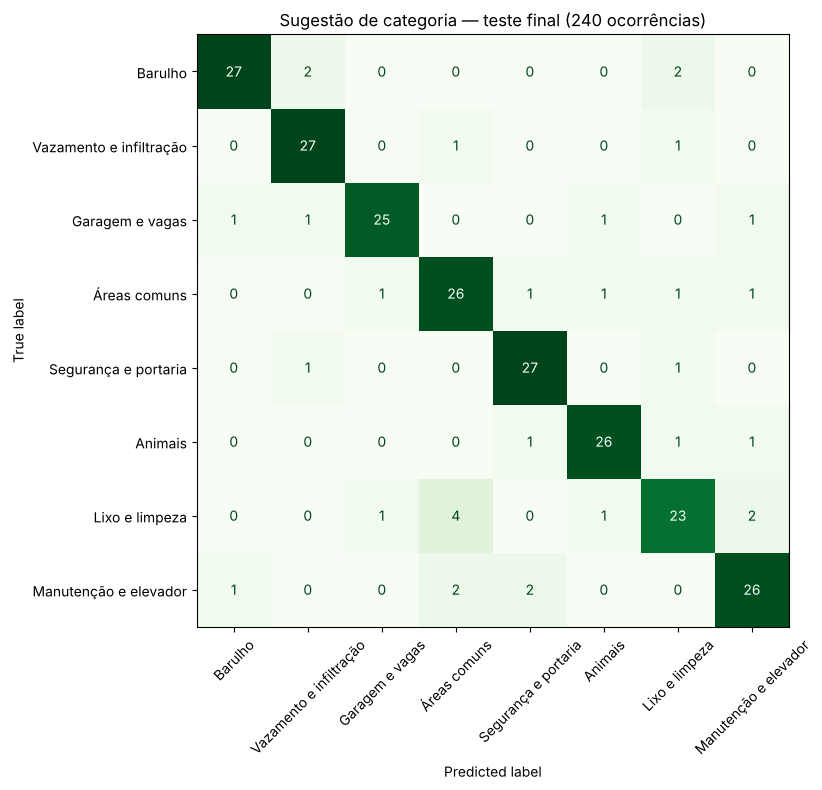

                         Barulho  Vazamento e infiltração  Garagem e vagas  Áreas comuns  Segurança e portaria  Animais  Lixo e limpeza  Manutenção e elevador
Barulho                       27                        2                0             0                     0        0               2                      0
Vazamento e infiltração        0                       27                0             1                     0        0               1                      0
Garagem e vagas                1                        1               25             0                     0        1               0                      1
Áreas comuns                   0                        0                1            26                     1        1               1                      1
Segurança e portaria           0                        1                0             0                    27        0               1                      0
Animais                        0              

In [6]:
modelo = candidatos[escolhido]
modelo.fit(X_treino, y_treino)
prev = modelo.predict(X_teste)
referencia = DummyClassifier(strategy='most_frequent').fit(X_treino, y_treino)
acc = accuracy_score(y_teste, prev)
f1m = f1_score(y_teste, prev, average='macro')
acc_ref = accuracy_score(y_teste, referencia.predict(X_teste))
print(f'TESTE FINAL — acurácia {acc:.4f} | F1 macro {f1m:.4f} | referência {acc_ref:.4f}')
print()
print(classification_report(y_teste, prev, digits=3))

ordem = CATEGORIAS
cm = confusion_matrix(y_teste, prev, labels=ordem)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=ordem).plot(ax=ax, cmap='Greens', xticks_rotation=45, colorbar=False)
ax.set_title('Sugestão de categoria — teste final (%d ocorrências)' % len(y_teste))
plt.tight_layout()
plt.savefig(os.path.join(PASTA_ASSETS, 'ocorrencias-matriz.png'), dpi=120, bbox_inches='tight')
plt.show()
print(pd.DataFrame(cm, index=ordem, columns=ordem).to_string())

**Resultado do teste:** acurácia **0,8625** (207 de 240) e F1 macro **0,8634**, contra **0,1292** da referência.

- Melhores categorias: *Animais*, *Barulho*, *Garagem*, *Segurança* e *Vazamento*, com F1 entre 0,893 e 0,900.
- Mais difícil: **Lixo e limpeza** (sensibilidade 0,742, F1 0,767). Pela matriz, 4 ocorrências de lixo foram previstas como *Áreas comuns* e 2 como *Manutenção*. Faz sentido: lixo aparece em hall, pilotis e escada, que também são locais de áreas comuns e de manutenção.
- *Áreas comuns* tem a menor precisão (0,788): ela "atrai" ocorrências de outras categorias que citam locais compartilhados.
- O teste (0,8625) ficou um pouco acima da média de validação (0,8458), dentro da variação esperada para 240 casos.

In [7]:
# Onde o modelo erra? Erros no teste separados pelo tipo de ruído simulado.
teste = base.loc[X_teste.index, ['texto', 'categoria', 'ruido']].copy()
teste['prevista'] = prev
teste['acertou'] = teste['categoria'] == teste['prevista']
print('Acurácia no teste por tipo de registro:')
print(teste.groupby('ruido')['acertou'].agg(['mean', 'count']).round(3).to_string())
print('\nAlguns erros em textos "limpos" (sem ruído simulado):')
print(teste[(~teste['acertou']) & (teste['ruido'] == 'nenhum')].head(8)[['texto', 'categoria', 'prevista']].to_string(index=False))

Acurácia no teste por tipo de registro:
                   mean  count
ruido                         
generico          0.308     13
generico+trocado  1.000      1
nenhum            0.985    205
rotulo_trocado    0.000     21

Alguns erros em textos "limpos" (sem ruído simulado):
                               texto      categoria     prevista
Lixeira sem separacao de reciclaveis Lixo e limpeza Áreas comuns
Lixeira sem separação de recicláveis Lixo e limpeza Áreas comuns
Lixeira sem separacao de reciclaveis Lixo e limpeza Áreas comuns


**Onde estão os erros?** Este é, para mim, o resultado mais importante do experimento:

- nos **205 textos limpos**, o modelo acerta **98,5%** (202);
- nos **21 com categoria trocada**, acerta **0%**: o modelo prevê a categoria "certa" pelo texto, e o rótulo errado conta como erro;
- nas **13 descrições genéricas**, acerta 30,8%, ou seja, praticamente chute.

Os três erros em textos limpos são a mesma frase: "Lixeira sem separação de recicláveis", prevista como *Áreas comuns*. Nesse caso, a palavra "lixeira" não basta para o modelo, e o resto da frase não tem termos de lixo.

**Conclusão:** neste cenário, o teto do modelo é a **qualidade da categorização humana**. No projeto real, isso torna ainda mais importante a categorização em dupla com cálculo de concordância que já está prevista. Rótulos ruins no treino viram sugestões ruins.

## 5. Limiar de confiança: quando pré-selecionar a categoria

No formulário do sistema, prefiro **não sugerir nada** a sugerir com pouca confiança. Escolho o limiar com as probabilidades de validação cruzada **no treino** e uso o teste só para confirmar.

In [8]:
# Limiar de confiança: só pré-selecionar a categoria quando a maior probabilidade passa do limiar.
# O limiar é escolhido com probabilidades fora da dobra no TREINO; o teste só confirma.
if hasattr(modelo, 'predict_proba'):
    modelo_proba = modelo
    proba_cv = cross_val_predict(candidatos[escolhido], X_treino, y_treino, cv=cv, method='predict_proba')
else:  # LinearSVC não tem probabilidade: calibramos dentro do treino
    modelo_proba = CalibratedClassifierCV(candidatos[escolhido], cv=5).fit(X_treino, y_treino)
    proba_cv = cross_val_predict(CalibratedClassifierCV(candidatos[escolhido], cv=5), X_treino, y_treino,
                                 cv=cv, method='predict_proba')
classes = np.array(sorted(y_treino.unique()))

def tabela_limiar(proba, y_real, limiares):
    conf = proba.max(axis=1)
    pred = classes[proba.argmax(axis=1)]
    linhas = []
    for lim in limiares:
        mask = conf >= lim
        linhas.append({'limiar': lim, 'cobertura': mask.mean(),
                       'n_sugeridas': int(mask.sum()),
                       'acuracia_nas_sugeridas': (pred[mask] == np.asarray(y_real)[mask]).mean() if mask.any() else np.nan})
    return pd.DataFrame(linhas)

limiares = [0.0, 0.3, 0.4, 0.5, 0.6, 0.7]
lim_treino = tabela_limiar(proba_cv, y_treino, limiares)
print('Validação cruzada no treino:')
print(lim_treino.round(3).to_string(index=False))
proba_teste = modelo_proba.predict_proba(X_teste)
lim_teste = tabela_limiar(proba_teste, y_teste, limiares)
print('\nTeste (confirmação, sem nova escolha):')
print(lim_teste.round(3).to_string(index=False))

Validação cruzada no treino:
 limiar  cobertura  n_sugeridas  acuracia_nas_sugeridas
    0.0      1.000          720                   0.846
    0.3      0.907          653                   0.890
    0.4      0.796          573                   0.901
    0.5      0.607          437                   0.899
    0.6      0.374          269                   0.900
    0.7      0.135           97                   0.907

Teste (confirmação, sem nova escolha):
 limiar  cobertura  n_sugeridas  acuracia_nas_sugeridas
    0.0      1.000          240                   0.862
    0.3      0.921          221                   0.905
    0.4      0.829          199                   0.910
    0.5      0.683          164                   0.902
    0.6      0.454          109                   0.927
    0.7      0.242           58                   0.931


**Escolha do limiar (feita no treino):**

| Limiar | Cobertura (validação no treino) | Acurácia nas sugeridas (treino) | Cobertura (teste) | Acurácia nas sugeridas (teste) |
| --- | --- | --- | --- | --- |
| sem limiar | 100% | 0,846 | 100% | 0,862 |
| 0,3 | 90,7% | 0,890 | 92,1% | 0,905 |
| **0,4** | **79,6%** | **0,901** | **82,9%** | **0,910** |
| 0,5 | 60,7% | 0,899 | 68,3% | 0,902 |
| 0,6 | 37,4% | 0,900 | 45,4% | 0,927 |

Escolhi **0,4**. Passar de 0,4 para 0,5 corta 19 pontos de cobertura sem ganho de acerto no treino. No teste, com 0,4, o sistema pré-selecionaria a categoria em 82,9% das ocorrências, acertando 91,0% delas; nas demais, o campo fica em branco, como no livro de hoje. As probabilidades da regressão logística com 8 classes são "achatadas" (raramente passam de 0,7), por isso limiares altos cortam demais.

## 6. Exemplos com textos novos

In [9]:
novos_textos = [
    'Som muito alto no apto XXX depois da meia-noite',
    'Água pingando do teto do banheiro, acho que vem do vizinho de cima',
    'Tem um carro parado na minha vaga desde cedo',
    'Elevador social parou entre o 2º e o 3º andar',
    'Portão da garagem não fecha e ficou aberto de madrugada',
    'Cachorro fazendo xixi no hall do bloco X',
    'Sacos de lixo largados na escada de incêndio',
    'Brinquedo do parquinho com parafuso solto',
    'Elevador fazendo barulho estranho',
    'Favor verificar',
]
proba_novos = modelo_proba.predict_proba(pd.Series(novos_textos))
exemplos = pd.DataFrame({'texto': novos_textos,
                         'categoria_sugerida': classes[proba_novos.argmax(axis=1)],
                         'confianca': proba_novos.max(axis=1).round(3)})
exemplos['segunda_opcao'] = [classes[np.argsort(p)[-2]] for p in proba_novos]
print(exemplos.to_string(index=False))

                                                             texto      categoria_sugerida  confianca           segunda_opcao
                   Som muito alto no apto XXX depois da meia-noite                 Barulho      0.731    Segurança e portaria
Água pingando do teto do banheiro, acho que vem do vizinho de cima Vazamento e infiltração      0.392                 Barulho
                      Tem um carro parado na minha vaga desde cedo         Garagem e vagas      0.551   Manutenção e elevador
                     Elevador social parou entre o 2º e o 3º andar   Manutenção e elevador      0.490          Lixo e limpeza
           Portão da garagem não fecha e ficou aberto de madrugada    Segurança e portaria      0.541   Manutenção e elevador
                          Cachorro fazendo xixi no hall do bloco X                 Animais      0.514 Vazamento e infiltração
                      Sacos de lixo largados na escada de incêndio          Lixo e limpeza      0.512            Áreas

**Leitura dos exemplos** (textos escritos por mim, fora dos dados gerados):

- Com o limiar de 0,4, seriam pré-selecionadas: "Som muito alto..." → *Barulho* (0,731); "carro parado na minha vaga" → *Garagem* (0,551); "Elevador social parou..." → *Manutenção* (0,490); "Cachorro fazendo xixi no hall" → *Animais* (0,514); "Sacos de lixo largados..." → *Lixo* (0,512); e "Elevador fazendo barulho estranho" → *Manutenção* (0,605), com *Barulho* como segunda opção. O modelo não se deixou levar só pela palavra "barulho".
- "Portão da garagem não fecha e ficou aberto de madrugada" → *Segurança e portaria* (0,541), com *Manutenção* em segundo lugar. Os dois rótulos seriam defensáveis. É um caso em que mostrar as **duas primeiras opções** ajuda mais do que forçar uma.
- **Ficariam sem sugestão** (abaixo de 0,4): o vazamento descrito com palavras diferentes das que usei ("Água pingando do teto...", 0,392, mas a sugestão estaria certa), o "Brinquedo do parquinho com parafuso solto" (0,394) e "Favor verificar" (0,224). Para o último, não sugerir nada é exatamente o comportamento desejado.

## 7. Registro dos resultados

In [10]:
resultados = {
    'autor': 'Ramon Guilherme Marques do Nascimento', 'semente': SEMENTE,
    'n_total': int(len(base)), 'n_treino': int(len(X_treino)), 'n_teste': int(len(X_teste)),
    'ruido': base['ruido'].value_counts().to_dict(),
    'validacao_cruzada': tabela.round(4).to_dict(orient='records'),
    'escolhido': escolhido,
    'acuracia_teste': float(acc), 'f1_macro_teste': float(f1m), 'acuracia_referencia': float(acc_ref),
    'relatorio_por_categoria': {k: {m: round(float(v2), 4) for m, v2 in v.items()}
                          for k, v in classification_report(y_teste, prev, output_dict=True).items()
                          if isinstance(v, dict)},
    'matriz_confusao': {'ordem': ordem, 'valores': cm.tolist()},
    'acuracia_por_ruido_teste': teste.groupby('ruido')['acertou'].mean().round(4).to_dict(),
    'limiar_treino_cv': lim_treino.round(4).to_dict(orient='records'),
    'limiar_teste': lim_teste.round(4).to_dict(orient='records'),
    'exemplos': exemplos.to_dict(orient='records'),
    'python': sys.version.split()[0], 'sklearn': sklearn.__version__,
    'pandas': pd.__version__, 'numpy': np.__version__}
with open('resultados_ocorrencias.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=float)
print('resultados_ocorrencias.json gravado.')

resultados_ocorrencias.json gravado.


## Conclusões e limites

- **Resultado calculado:** TF-IDF de caracteres + regressão logística, escolhido por validação cruzada no treino, teve acurácia de 0,8625 e F1 macro de 0,8634 no teste, contra 0,1292 da referência. Com limiar de 0,4, cobre 82,9% das ocorrências com 91,0% de acerto.
- **Interpretação:** quase todos os erros vêm de rótulos trocados e de descrições genéricas, e não da dificuldade do texto. A qualidade da categorização humana define o teto do modelo.
- **Hipótese:** com o livro real, a acurácia deve cair, porque a escrita à mão transcrita é mais variada que meus modelos de frase e algumas categorias serão raras. Só um teste com registros reais, separados por período (treinar com meses antigos e testar nos mais recentes), responde isso.
- **Dados sintéticos não validam o uso real.** O vocabulário e as associações texto → categoria fui eu que defini.
- **Privacidade:** o texto livre pode conter nomes, números de apartamento e placas. No sistema real, o modelo só deveria ser treinado com descrições já anonimizadas (como prevê a transcrição do projeto) e rodar no próprio servidor, sem enviar texto a terceiros.
- **Uso responsável:** a sugestão é só um pré-preenchimento. O morador ou o porteiro confirma ou troca, e o síndico pode recategorizar. A categoria não deve definir sozinha prioridade nem punição.

## Referências

- SCIKIT-LEARN. *Working with text data*; *TfidfVectorizer*; *LogisticRegression*; *Pipeline*. Disponível em: https://scikit-learn.org/stable/user_guide.html. Acesso em: 16 out. 2026.
- VIEIRA, A. R. S.; NASCIMENTO, R. G. M. *Livro de ocorrências digital para condomínios residenciais: definição do projeto de Ciência de Dados*. UDF, 2026 ([documento](../../Unidade_3_Gestao_de_Projetos_em_Ciencia_de_Dados/Definicao-Projeto-Ciencia-de-Dados.md)).